In [1]:
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
CSV_PATH = "../data/raw/raw_adzuna_data.csv"
df = pd.read_csv(CSV_PATH)

In [ ]:
df.shape

(2403, 17)

## Phân tích loại hợp đồng

In [9]:
for col in ["contract_type", "contract_time"]:
    print(f"\nPhân phối của {col}:")
    display(
        df[col]
        .value_counts(dropna=False)
        .rename_axis(col)
        .reset_index(name="count")
    )


Phân phối của contract_type:


,contract_type,count
0,permanent,2403



Phân phối của contract_time:


,contract_time,count
0,full_time,2403


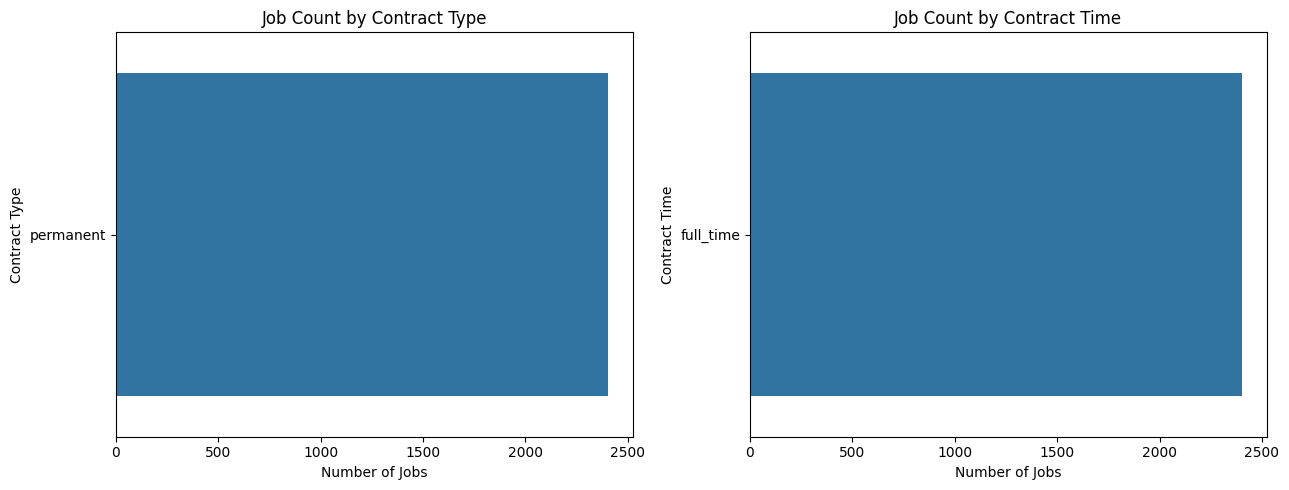

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(data=df, y="contract_type", ax=axes[0])
axes[0].set_title("Job Count by Contract Type")
axes[0].set_xlabel("Number of Jobs")
axes[0].set_ylabel("Contract Type")

sns.countplot(data=df, y="contract_time", ax=axes[1])
axes[1].set_title("Job Count by Contract Time")
axes[1].set_xlabel("Number of Jobs")
axes[1].set_ylabel("Contract Time")

plt.tight_layout()
plt.show()

## Phân tích nhóm ngành nghề

In [10]:
def parse_dict(value):
    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, dict) else {}
    except (ValueError, SyntaxError, TypeError):
        return {}

category_data = df["category"].apply(parse_dict)

df["category_label"] = category_data.apply(
    lambda x: x.get("label")
)

df["category_tag"] = category_data.apply(
    lambda x: x.get("tag")
)

display(df[["category", "category_label", "category_tag"]].head())

,category,category_label,category_tag
0,"{'tag': 'it-jobs', 'label': 'IT Jobs', '__CLAS...",IT Jobs,it-jobs
1,"{'tag': 'engineering-jobs', 'label': 'Engineer...",Engineering Jobs,engineering-jobs
2,"{'label': 'IT Jobs', 'tag': 'it-jobs', '__CLAS...",IT Jobs,it-jobs
3,"{'label': 'IT Jobs', 'tag': 'it-jobs', '__CLAS...",IT Jobs,it-jobs
4,"{'label': 'Engineering Jobs', 'tag': 'engineer...",Engineering Jobs,engineering-jobs


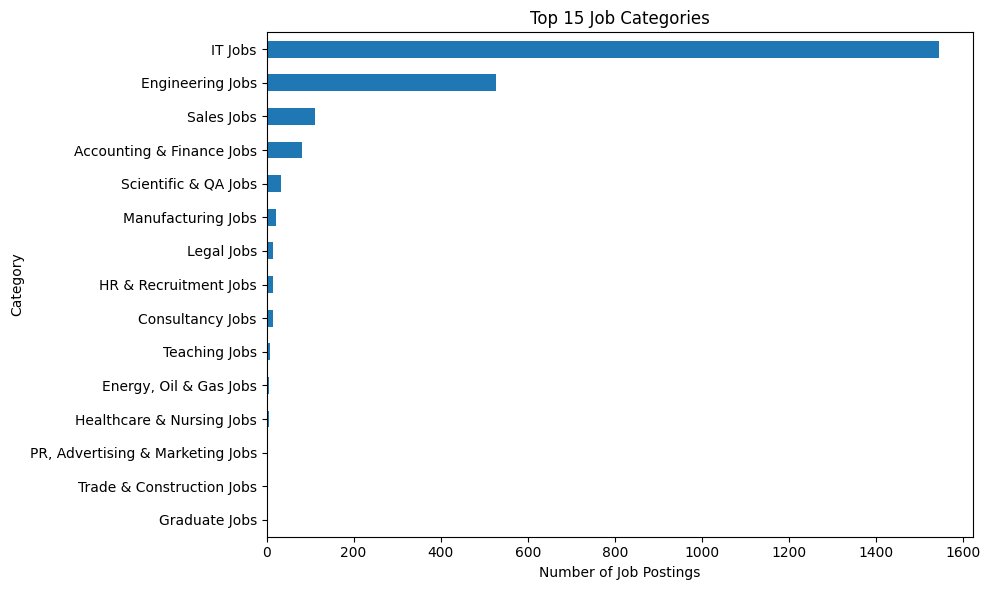

In [11]:
top_categories = df["category_label"].value_counts().head(15)

plt.figure(figsize=(10, 6))
top_categories.sort_values().plot(kind="barh")

plt.title("Top 15 Job Categories")
plt.xlabel("Number of Job Postings")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

## Top chức danh công việc

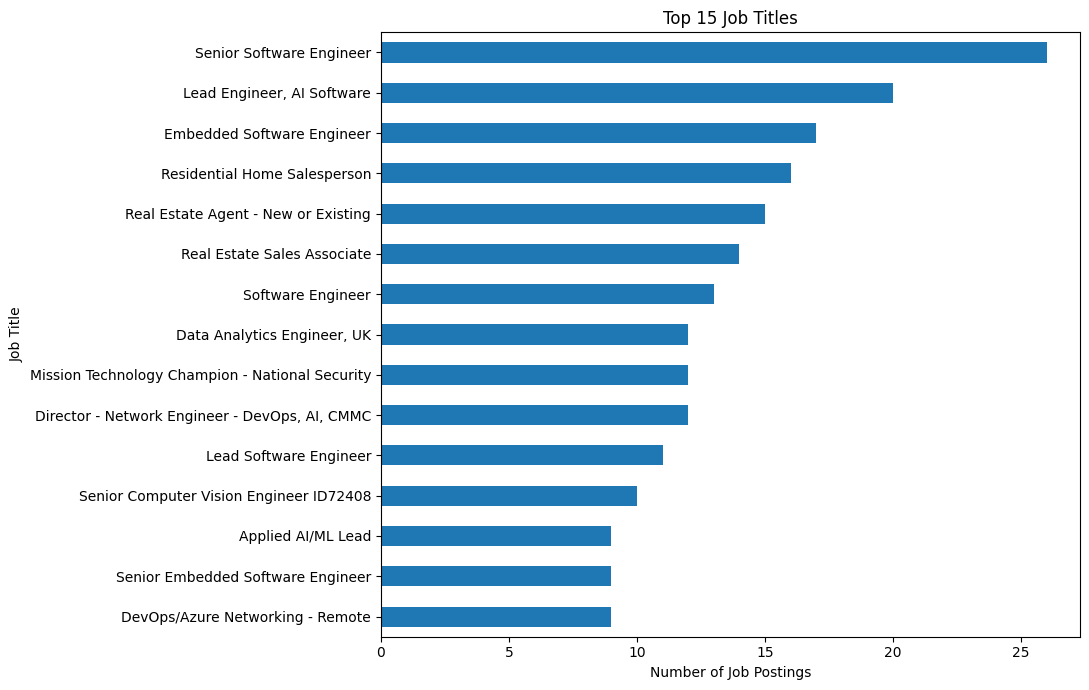

In [12]:
top_titles = df["title"].value_counts().head(15)

plt.figure(figsize=(11, 7))
top_titles.sort_values().plot(kind="barh")

plt.title("Top 15 Job Titles")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Title")

plt.tight_layout()
plt.show()

# Phân tích targets là mức lương

In [13]:
salary_cols = ["salary_min", "salary_max"]

display(df[salary_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
salary_min,2403.0,156239.376184,72618.293331,0.0,109754.320,143860.77,188744.555,535280.44
salary_max,2403.0,184644.097782,76880.800208,1.0,130645.365,177700.00,234000.000,600000.00


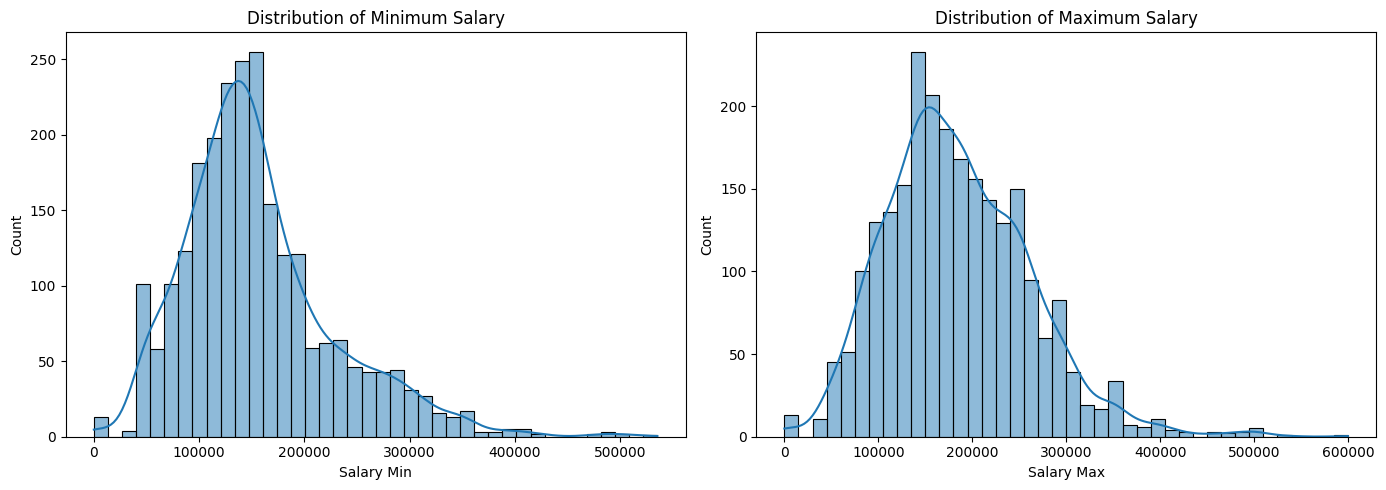

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df, x="salary_min", bins=40, kde=True, ax=axes[0]
)
axes[0].set_title("Distribution of Minimum Salary")
axes[0].set_xlabel("Salary Min")

sns.histplot(
    data=df, x="salary_max", bins=40, kde=True, ax=axes[1]
)
axes[1].set_title("Distribution of Maximum Salary")
axes[1].set_xlabel("Salary Max")

plt.tight_layout()
plt.show()

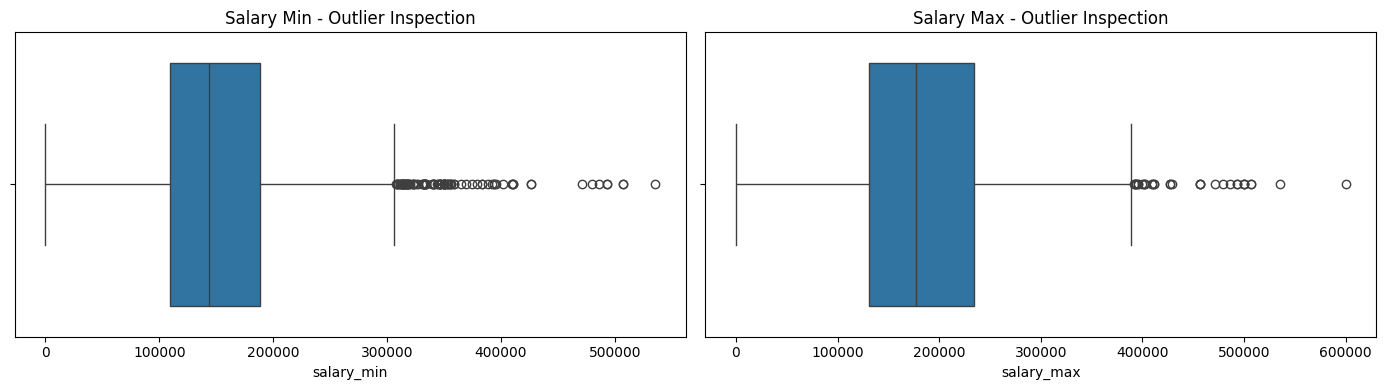

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=df["salary_min"], ax=axes[0])
axes[0].set_title("Salary Min - Outlier Inspection")

sns.boxplot(x=df["salary_max"], ax=axes[1])
axes[1].set_title("Salary Max - Outlier Inspection")

plt.tight_layout()
plt.show()